# Семинар 04. Сопровождение объектов
**Цель:** реализовать минимальный цикл `predict → associate → update → manage tracks` на ИК-видео Anti-UAV, а затем обсудить перенос на радиолокационные отметки.

**Самое главное в семинаре:** разница между детекцией и сопровождением, роль фильтра Калмана, Венгерский алгоритм и жизненный цикл трека.

> Anti-UAV здесь — **ИК-видеоданные, а не радиолокационные измерения**. Мы используем их для обучения общим принципам MOT. В учебном формате вход — готовые bbox, а не исходный протокол соревнования Anti-UAV.

## 0. Подготовка среды
Положите `tracking_utils.py` рядом с ноутбуком. Укажите путь к `train`, внутри которого находятся каталоги `images/` и `labels/`.

В Colab можно загрузить ZIP через интерфейс Files и распаковать его. Для мини-примера имя каталога — `anti_uav_example/train`. При использовании полного набора данных измените только `DATA_DIR`.

Нужны `numpy`, `scipy`, `matplotlib`, `pillow`, `pandas`. Установите при необходимости: `%pip install numpy scipy matplotlib pillow pandas`.

In [7]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from tracking_utils import (discover_sequences, strip_ids, noisy_measurements,
    bbox_iou, match_cost, KalmanBox, SortLikeTracker, run_tracker, evaluate, save_mot)
import pandas as pd 

DATA_DIR = Path("data/4th_Anti-UAV/train")  # измените при необходимости
sequences = discover_sequences(DATA_DIR)
print('Последовательности:', {key: len(val) for key, val in sequences.items()})
seq_name, frames = next(iter(sequences.items()))
print('Пример кадра:', frames[0].number, 'GT:', frames[0].gt)

Последовательности: {'4au_01_1751_0250-1750': 1500, '4au_01_4485_1167-2666': 1467, '4au_04_8618_1215-2714': 1500, '4au_11_1': 487, '4au_12_1': 714, '4au_15_1': 619, '4au_20190925_101846_1_3': 1000, '4au_20190925_101846_1_5': 1000, '4au_20190925_111757_1_1': 1000, '4au_20190925_111757_1_2': 1000, '4au_20190925_111757_1_6': 1000, '4au_20190925_111757_1_7': 1000, '4au_20190925_111757_1_8': 948, '4au_20190925_111757_1_9': 1000, '4au_20190925_124000_1_5': 1000, '4au_20190925_124612_1_1': 1000, '4au_20190925_124612_1_2': 1000, '4au_20190925_130434_1_3': 989, '4au_20190925_130434_1_4': 1000, '4au_20190925_131530_1_1': 1000, '4au_20190925_131530_1_5': 1000, '4au_20190925_131530_1_7': 923, '4au_20190925_134301_1_2': 1000, '4au_20190925_134301_1_7': 1000, '4au_20190925_134301_1_9': 619, '4au_20190925_140917_1_1': 1000, '4au_20190925_140917_1_5': 1000, '4au_20190925_140917_1_6': 1000, '4au_20190925_140917_1_7': 1000, '4au_20190925_140917_1_8': 404, '4au_20190925_141417_1_1': 1000, '4au_20190925_1

### Важно: шестая колонка — истинный `track_id`
Строка разметки: `class_id x_center y_center width height track_id`; четыре геометрических числа нормированы на ширину и высоту изображения.

`track_id` используется **только для GT и оценки**. Перед вызовом трекера `strip_ids()` удаляет истинный ID, создавая `[x1,y1,x2,y2,score]` в пикселях. Передавать `gt[:,4]` на вход трекеру нельзя.

In [40]:
# it = iter(sequences.items())
seq_name, frames = next(it)
seq_name

'4au_20190925_111757_1_6'

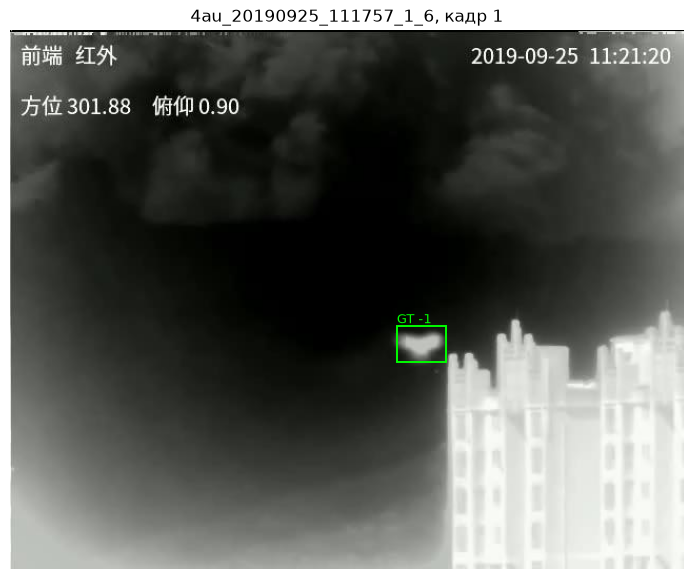

In [41]:
def plot_frame(frame, predictions=None, title=''):
    fig, ax = plt.subplots(figsize=(11, 7))
    ax.imshow(Image.open(frame.image_path))
    for x1,y1,x2,y2,tid,_ in frame.gt:
        ax.add_patch(plt.Rectangle((x1,y1),x2-x1,y2-y1,fill=False,edgecolor='lime',lw=1.4))
        ax.text(x1,y1-3,f'GT {int(tid)}',color='lime',fontsize=9)
    if predictions is not None:
        for x1,y1,x2,y2,tid in predictions:
            ax.add_patch(plt.Rectangle((x1,y1),x2-x1,y2-y1,fill=False,edgecolor='orange',lw=1.5,ls='--'))
            ax.text(x1,y2+10,f'pred {int(tid)}',color='orange',fontsize=9)
    ax.set_title(title or f'{seq_name}, кадр {frame.number}');ax.axis('off')
    plt.show()
plot_frame(frames[0])

## 1. Постановка MOT (10 минут)
На каждом кадре есть **детекции** — прямоугольники без идентичности. Требуется восстановить **траектории**: объекту должен соответствовать устойчивый ID.

Обсудите: (a) что произойдёт, если объекты сблизятся; (b) что произойдёт при одной пропущенной детекции; (c) зачем нужен прогноз положения, а не только расстояние до предыдущего bbox.

В этом мини-примере одновременно присутствуют несколько объектов; новые ID могут появляться по ходу ролика.

In [42]:
gt_ids = sorted({int(row[4]) for fr in frames for row in fr.gt})
print('GT IDs:', gt_ids)
print('Детекций в первых 10 кадрах:', [len(f.gt) for f in frames[:10]])
print('Проверяем отсутствие GT ID на входе:', strip_ids(frames[0].gt).shape)
assert strip_ids(frames[0].gt).shape[1] == 5

GT IDs: [-1]
Детекций в первых 10 кадрах: [1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
Проверяем отсутствие GT ID на входе: (1, 5)


## 2. Фильтр Калмана: прогноз и коррекция (15 минут)
Используем состояние `x = [cx, cy, vx, vy, w, h]` и наблюдение `z = [cx, cy, w, h]`.

При постоянной скорости на интервале `dt`: `cx ← cx + vx·dt`, `cy ← cy + vy·dt`. Калман хранит ещё ковариацию `P`, обновляет её при прогнозе (`Q`), а при получении новой детекции использует невязку и усиление `K` с учётом ошибки измерений (`R`). Если детекция пропала, выполняем **только predict**.

**Пояснение к моделированию:** физические параметры движения здесь заданы в пикселях/кадр, а не в метрах/с. FPS в предоставленном CSV не заполнен, поэтому физические скорости не восстанавливаем.

In [137]:
kf = KalmanBox(frames[0].gt[0,:4])
print('x до прогноза:', np.round(kf.x,0), "bbox:", np.round(kf.box(), 0))
kf.update(frames[1].gt[0,:4])
kf.update(frames[2].gt[0,:4])
print('x после 1-ой коррекции:', np.round(kf.x,0), "bbox:", np.round(kf.box(), 0))
n = 10
for t in range(3,n):
    print('prediction',t, np.round(kf.predict(dt=1),0))
kf.update(frames[n].gt[0,:4])
print(f'x после коррекции на кадре {n}:', np.round(kf.x,0), "bbox:", np.round(kf.box(), 0))
print('истинный x:', np.round(frames[n].gt[0,:4],0))

x до прогноза: [313. 276.   0.   0.  14.  11.] bbox: [306. 270. 320. 281.]
x после 1-ой коррекции: [322. 275.   0.   0.  14.  12.] bbox: [315. 269. 329. 281.]
prediction 3 [315. 269. 329. 281.]
prediction 4 [315. 269. 329. 281.]
prediction 5 [315. 269. 329. 281.]
prediction 6 [315. 269. 329. 281.]
prediction 7 [315. 269. 329. 281.]
prediction 8 [315. 269. 329. 281.]
prediction 9 [315. 269. 329. 281.]
x после коррекции на кадре 10: [349. 275.   4.  -0.  14.  12.] bbox: [342. 269. 356. 280.]
истинный x: [343. 269. 356. 280.]


**Обсуждение:** почему начальная скорость равна нулю? Почему после нескольких наблюдений фильтр может оценить скорость? Что произойдёт при чрезмерно малом `R` или `Q`?

## 3. Ассоциация: IoU, gating и венгерский алгоритм (15 минут)
Матрица IoU сопоставляет предсказанные боксы с текущими детекциями. Стоимость `1 − IoU`, а `IoU < threshold` означает запрещённую пару (gating). Hungarian минимизирует общую стоимость назначений и возвращает соответствия один-к-одному.

**Вопрос:** почему нельзя просто независимо взять ближайшую детекцию для каждого трека?

In [67]:
seq_name, frames = next(iter(sequences.items()))

In [68]:
first = strip_ids(frames[0].gt)
second = strip_ids(frames[1].gt)
sim = bbox_iou(first[:,:4],second[:,:4])
pairs,unmatched_tracks,unmatched_dets = match_cost(1-sim,sim>=.1)
print('IoU matrix',np.round(sim,3))
print('Пары индексов:',pairs,'unmatched tracks:',unmatched_tracks,'unmatched detections:',unmatched_dets)
assert len({i for i,j in pairs})==len(pairs)
assert len({j for i,j in pairs})==len(pairs)

IoU matrix [[0.314]]
Пары индексов: [(0, 0)] unmatched tracks: [] unmatched detections: []


In [69]:
first = strip_ids(frames[0].gt)
second = strip_ids(frames[1].gt)
sim = bbox_iou(first[:,:4],second[:,:4])
pairs,unmatched_tracks,unmatched_dets = match_cost(1-sim,sim>=.8)
print('IoU matrix',np.round(sim,3))
print('Пары индексов:',pairs,'unmatched tracks:',unmatched_tracks,'unmatched detections:',unmatched_dets)
assert len({i for i,j in pairs})==len(pairs)
assert len({j for i,j in pairs})==len(pairs)

IoU matrix [[0.314]]
Пары индексов: [] unmatched tracks: [0] unmatched detections: [0]


## 4. Полный цикл трекера (20 минут)
Ниже запускаем **учебную SORT-подобную адаптацию**. В оригинальном SORT — Kalman + Hungarian + IoU по bbox. У нас та же общая схема, но своя параметризация состояния и упрощённое управление подтверждением треков.

`max_age` — максимальный пропуск в номерах кадров; `min_hits` — сколько успешных попаданий требуется до вывода ID. Не путайте «трек существует в памяти» и «трек выводится в результат».

In [76]:
# it = iter(sequences.items())
seq_name, frames = next(it)
seq_name

'4au_20190925_111757_1_8'

Предсказанные ID первых кадров: [[1], [1], [1], [1], [1], [1], [1], [1], [1], [1]]


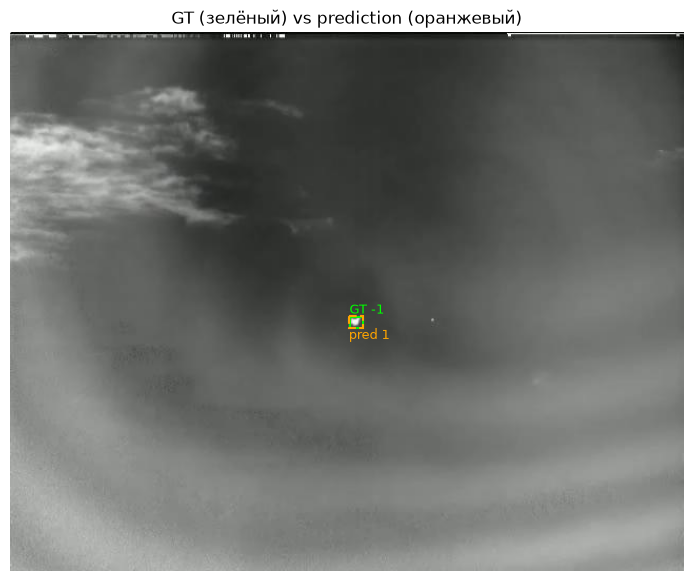

In [101]:
tracker = SortLikeTracker(association='iou',iou_threshold=.1,max_age=3,min_hits=1)
pred_ideal = run_tracker(frames,tracker,mode='ideal')
print('Предсказанные ID первых кадров:', [[int(p[-1]) for p in row] for row in pred_ideal[:10]])
plot_frame(frames[20],pred_ideal[20],title='GT (зелёный) vs prediction (оранжевый)')

**Мини-эксперимент:** на том же `frames` сравните `min_hits=1` и `min_hits=3`. Почему при появлении объекта некоторое время может отсутствовать подтверждённая траектория?

In [105]:
print("Всего кадров:", len(frames))
for hits in (1,3, 5):
    pred = run_tracker(frames,SortLikeTracker(min_hits=hits),mode='ideal')
    print('min_hits =',hits,'число выведенных боксов =',sum(map(len,pred)))

Всего кадров: 1500
min_hits = 1 число выведенных боксов = 1500


min_hits = 3 число выведенных боксов = 1470
min_hits = 5 число выведенных боксов = 1455


In [106]:
print("Всего кадров:", len(frames))
for hits in (1,3, 5):
    pred = run_tracker(frames,SortLikeTracker(min_hits=hits),mode='noisy')
    print('min_hits =',hits,'число выведенных боксов =',sum(map(len,pred)))

Всего кадров: 1500


min_hits = 1 число выведенных боксов = 1483


min_hits = 3 число выведенных боксов = 1175


min_hits = 5 число выведенных боксов = 1076


## 5. От идеальных к шумным детекциям (10 минут)
В реальной системе детектор делает пропуски, ошибается в координатах и создаёт ложные объекты. Мы контролируем эти ошибки синтетически; это **не равно** настоящим выходам обученного детектора.

Используем одинаковый `seed=42` при сравнении трекеров — иначе шум меняется и сравнение некорректно.

In [88]:
it = iter(sequences.items())
seq_name, frames = next(it)
noisy
seq_name

'4au_01_1751_0250-1750'

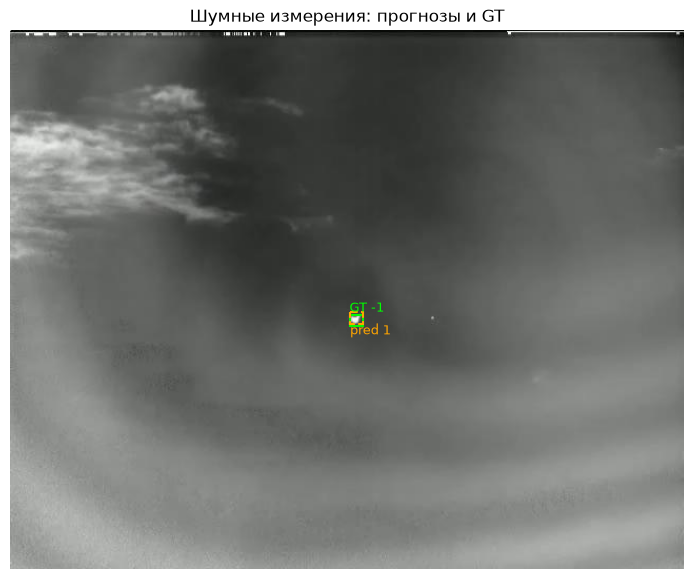

,Детекции,HOTA,DetA,AssA,MOTA,IDF1,IDSW
0,Идеальные,0.668,0.850,0.526,0.99,0.755,15
1,С шумом,0.151,0.464,0.049,0.40,0.118,37


In [136]:
noisy = run_tracker(frames,SortLikeTracker(association='iou',iou_threshold=.05, max_age=3, min_hits=1),
                    mode='noisy',seed=42)
pred_ideal = run_tracker(frames,SortLikeTracker(association='iou',iou_threshold=.05,max_age=3,min_hits=1)
                         ,mode='ideal',seed=42)
df_dets = pd.DataFrame(columns = ["Детекции", 'HOTA','DetA','AssA','MOTA','IDF1','IDSW'])
i = 0
for label,outputs in [('Идеальные',pred_ideal),('С шумом',noisy)]:
    m=evaluate(frames,outputs)
    s = [label] + [round(m[k],3) for k in ('HOTA','DetA','AssA','MOTA','IDF1','IDSW')]
    df_dets.loc[i] = s
    i += 1

plot_frame(frames[20],noisy[20],title='Шумные измерения: прогнозы и GT')
df_dets

### Мостик к радару: bbox против отметок-точек
Для видеодетекций подходит IoU; для радиолокационных отметок (дальность/азимут или декартовы координаты) IoU часто не определён. Меняем функцию стоимости на евклидово расстояние между центрами или расстояние Махаланобиса с учётом неопределённости.

**Оговорка:** координаты центров на ИК-видео всё ещё пиксельные; это не модель реальной точности радиолокационных измерений.

In [128]:
noisy = run_tracker(frames,SortLikeTracker(association='iou',iou_threshold=.05),mode='noisy',seed=42)
pred_center= run_tracker(frames,SortLikeTracker(association='center',distance_threshold=45.),
                        mode='noisy',seed=42)
df1 = pd.DataFrame(columns = ["Метод", 'HOTA','DetA','AssA','IDF1'])
i = 0
for label,out in [('IoU',noisy),('center',pred_center)]:
    m=evaluate(frames,out)
    s = [label] + [round(m[key],3) for key in ('HOTA','DetA','AssA','IDF1')]
    df1.loc[i] = s
    i += 1

df1

,Метод,HOTA,DetA,AssA,IDF1
0,IoU,0.151,0.464,0.049,0.118
1,center,0.375,0.467,0.301,0.487


In [135]:
%%time
pred_center= run_tracker(frames,SortLikeTracker(association='center',distance_threshold=45.),
                        mode='noisy',seed=42)
len(frames)

CPU times: total: 281 ms
Wall time: 272 ms


1500

## 6. Сохранение результата и ДЗ2 (5 минут)
Пишем результаты в 10-колоночный MOT-подобный формат: `frame,id,x,y,w,h,score,-1,-1,-1`. Нумерацию исходных кадров сохраняем. В итоговой работе будем оценивать каждую последовательность отдельно; не смешиваем track ID разных роликов.

In [94]:
save_mot('seminar_predictions.txt',frames,pred_center)
print('Готово: seminar_predictions.txt')

Готово: seminar_predictions.txt
